In [ ]:
# ==============================================================================
# CELL 1: Install & Import Libraries
# ==============================================================================
!pip install -q open_clip_torch datasets pandas numpy pillow torch torchvision pyarrow matplotlib

import os
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from datasets import load_dataset
import open_clip

# Thiết lập thiết bị tính toán
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"--> Using device: {device}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.1 MB/s eta 0:00:00
--> Using device: cuda


In [ ]:
# ==============================================================================
# CELL 2: Load Sample Dataset from Hugging Face (Flickr8k)
# ==============================================================================
print("--> Loading Flickr8k dataset sample from Hugging Face...")
# Tải tập test split của dataset jxie/flickr8k
raw_dataset = load_dataset("jxie/flickr8k", split="test")

# Chỉ lấy 100 mẫu cho lab demo
NUM_SAMPLES = 100
dataset_sample = raw_dataset.select(range(NUM_SAMPLES))

print(f"--> Dataset loaded successfully with {len(dataset_sample)} samples.")

# Lấy duy nhất caption_0 làm caption đại diện
sample_item = dataset_sample[0]
print("Sample structure:", sample_item.keys())
print("Example Caption (caption_0):", sample_item['caption_0'])

--> Loading Flickr8k dataset sample from Hugging Face...


README.md:   0%|          | 0.00/687 [00:00<?, ?B/s]

data/train-00000-of-00002-2f8f6bfa852eac(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00000-of-00002-2f8f6bfa852eac(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-2173151d8cd6c7(…): reconstructing file:   0%|          |  0.00B /  414MB            

data/train-00001-of-00002-2173151d8cd6c7(…): downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split:   0%|          | 0/6000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

--> Dataset loaded successfully with 100 samples.
Sample structure: dict_keys(['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'])
Example Caption (caption_0): The dogs are in the snow in front of a fence .


In [ ]:
# ==============================================================================
# CELL 3: Load OpenCLIP Model & Preprocess
# ==============================================================================
MODEL_NAME = 'ViT-B-32'
PRETRAINED = 'laion2b_s34b_b79k'

print(f"--> Loading OpenCLIP model: {MODEL_NAME} ({PRETRAINED})...")
model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED,
    device=device
)
tokenizer = open_clip.get_tokenizer(MODEL_NAME)
model.eval()
print("--> Model loaded and set to evaluation mode.")

--> Loading OpenCLIP model: ViT-B-32 (laion2b_s34b_b79k)...


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

--> Model loaded and set to evaluation mode.


In [ ]:
# ==============================================================================
# CELL 4: Batch Image Encoding & Feature Extraction
# ==============================================================================
BATCH_SIZE = 32
image_embeddings = []
metadata_records = []

os.makedirs("output_lab", exist_ok=True)

print("--> Extracting Image Embeddings in Batches...")
with torch.no_grad():
    for i in range(0, len(dataset_sample), BATCH_SIZE):
        batch_items = dataset_sample[i : i + BATCH_SIZE]

        # Preprocess danh sách ảnh PIL trong batch
        images_preprocessed = [preprocess(img.convert("RGB")) for img in batch_items['image']]
        images_tensor = torch.stack(images_preprocessed).to(device)

        # Forward pass qua OpenCLIP Image Encoder & L2 Normalize
        features = model.encode_image(images_tensor)
        features = F.normalize(features, dim=-1)

        image_embeddings.append(features.cpu().numpy())

        # Xây dựng metadata chỉ lưu caption_0
        for j, cap_0 in enumerate(batch_items['caption_0']):
            global_idx = i + j
            metadata_records.append({
                "index": global_idx,
                "image_id": f"flickr8k_frame_{global_idx:04d}",
                "caption": cap_0  # Chỉ lưu 1 caption duy nhất
            })

# Ghép toàn bộ batches thành ma trận N x D
image_embeddings_matrix = np.vstack(image_embeddings)
print(f"--> Image Embeddings Matrix Shape: {image_embeddings_matrix.shape}")

--> Extracting Image Embeddings in Batches...
--> Image Embeddings Matrix Shape: (100, 512)


In [ ]:
# ==============================================================================
# CELL 5: Save Embeddings (.npy) and Index Mapping (.parquet)
# ==============================================================================
NPY_PATH = "output_lab/image_embeddings.npy"
PARQUET_PATH = "output_lab/index_mapping.parquet"

# 1. Lưu ma trận embedding ra file .npy
np.save(NPY_PATH, image_embeddings_matrix)

# 2. Lưu index mapping & metadata ra file Parquet
df_mapping = pd.DataFrame(metadata_records)
df_mapping.to_parquet(PARQUET_PATH, index=False)

print(f"--> Saved Embeddings to: {NPY_PATH} ({os.path.getsize(NPY_PATH) / 1024:.2f} KB)")
print(f"--> Saved Index Mapping to: {PARQUET_PATH} ({os.path.getsize(PARQUET_PATH) / 1024:.2f} KB)")

--> Saved Embeddings to: output_lab/image_embeddings.npy (200.12 KB)
--> Saved Index Mapping to: output_lab/index_mapping.parquet (7.16 KB)


In [ ]:
# ==============================================================================
# CELL 6: Downstream Task - Text Querying & Dot Product Matching
# ==============================================================================
# Load lại dữ liệu từ đĩa để đảm bảo đúng luồng thực hành Save/Load
loaded_embeddings = np.load(NPY_PATH)
df_index = pd.read_parquet(PARQUET_PATH)

# Chuẩn bị Test Queries từ caption đã lưu
test_queries = []
ground_truth_indices = []

for idx, row in df_index.iterrows():
    # Sử dụng caption đại diện duy nhất
    caption_text = row['caption']
    test_queries.append(f"a photo of {caption_text}")
    ground_truth_indices.append(idx) # Vị trí đúng của ảnh tương ứng

print(f"--> Generated {len(test_queries)} Text Queries for Evaluation.")

# Encode toàn bộ Text Queries qua Text Encoder
print("--> Encoding Text Queries...")
text_tokens = tokenizer(test_queries).to(device)

with torch.no_grad():
    text_features = model.encode_text(text_tokens)
    text_features = F.normalize(text_features, dim=-1).cpu().numpy()

# Tích vô hướng (Dot Product / Cosine Similarity)
# [N_queries, D] x [D, N_images] -> [N_queries, N_images]
similarity_scores = np.dot(text_features, loaded_embeddings.T)
print(f"--> Similarity Matrix Shape: {similarity_scores.shape}")

--> Generated 100 Text Queries for Evaluation.
--> Encoding Text Queries...
--> Similarity Matrix Shape: (100, 100)


In [ ]:
# ==============================================================================
# CELL 7: Evaluate Retrieval Metrics (Recall@K and MRR)
# ==============================================================================
def evaluate_retrieval(sim_matrix, ground_truth, k_values=[1, 5, 10]):
    """
    Tính toán Recall@K và Mean Reciprocal Rank (MRR)
    """
    num_queries = sim_matrix.shape[0]
    recalls = {k: 0 for k in k_values}
    mrr_sum = 0.0

    # Sắp xếp chỉ số ảnh có điểm Cosine từ cao xuống thấp cho từng query
    top_indices = np.argsort(-sim_matrix, axis=1)

    for i in range(num_queries):
        target_idx = ground_truth[i]
        ranked_list = top_indices[i]

        # Tìm vị trí (rank 1-based) của đáp án đúng trong danh sách trả về
        rank = np.where(ranked_list == target_idx)[0][0] + 1

        # Cộng dồn Reciprocal Rank
        mrr_sum += 1.0 / rank

        # Cộng dồn Recall@K
        for k in k_values:
            if rank <= k:
                recalls[k] += 1

    results = {f"Recall@{k}": recalls[k] / num_queries for k in k_values}
    results["MRR"] = mrr_sum / num_queries
    return results

# Chạy đánh giá
metrics = evaluate_retrieval(similarity_scores, ground_truth_indices)

print("\n================ EVALUATION RESULTS ================")
for metric_name, val in metrics.items():
    if "Recall" in metric_name:
        print(f"  * {metric_name:10s}: {val * 100:.2f}%")
    else:
        print(f"  * {metric_name:10s}: {val:.4f}")
print("====================================================")


================ EVALUATION RESULTS ================
  * Recall@1  : 89.00%
  * Recall@5  : 98.00%
  * Recall@10 : 100.00%
  * MRR       : 0.9277


Query Text: 'Một bức ảnh của một bé gái đang ngồi trên bệ đong đưa 1 chân trong bồn rửa trong khi nắm vòi phun'
Target Image Index: 26



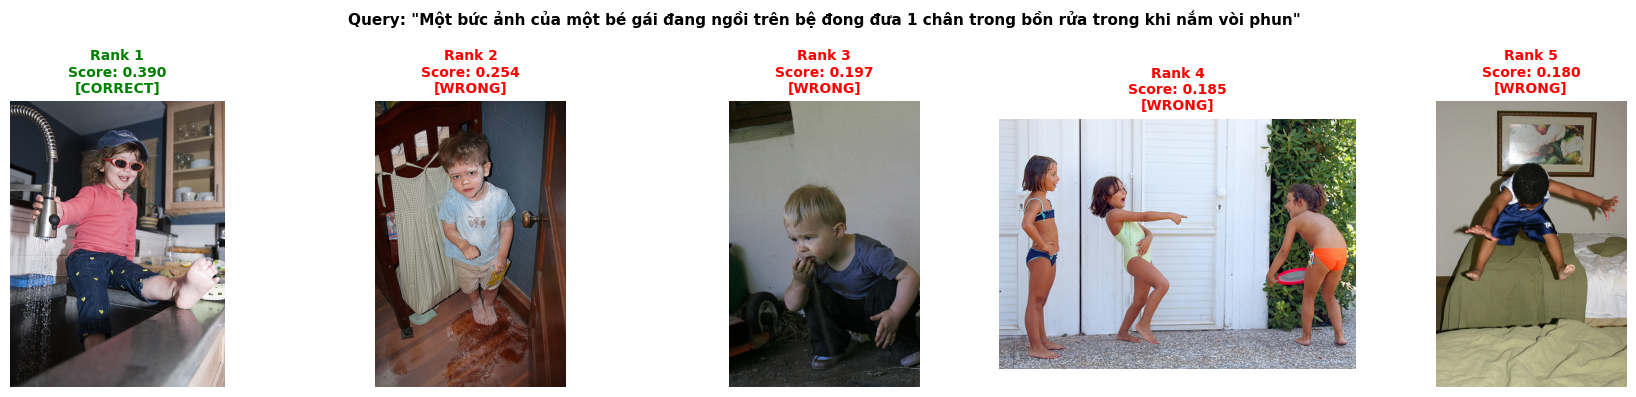

In [ ]:
# ==============================================================================
# CELL 8: Qualitative Visualization (Top-5 Retrieval Results)
# ==============================================================================
# Chọn 1 query mẫu bất kỳ để xem trực quan (ví dụ: query số 5)
QUERY_ID = 26
# sample_query_text = "a photo of A little girl is sitting on the counter dangling one foot in the sink whilst holding a dish jet washer ."
sample_query_text = "Một bức ảnh của một bé gái đang ngồi trên bệ đong đưa 1 chân trong bồn rửa trong khi nắm vòi phun"
correct_image_idx = ground_truth_indices[QUERY_ID]

# Lấy Top-5 kết quả tìm kiếm hàng đầu
top_5_retrieved_indices = np.argsort(-similarity_scores[QUERY_ID])[:5]

print(f"Query Text: '{sample_query_text}'")
print(f"Target Image Index: {correct_image_idx}\n")

# Vẽ 5 ảnh kết quả bằng Matplotlib
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
fig.suptitle(f"Query: \"{sample_query_text}\"", fontsize=11, fontweight='bold')

for rank_idx, img_idx in enumerate(top_5_retrieved_indices):
    score = similarity_scores[QUERY_ID][img_idx]
    retrieved_img = dataset_sample[int(img_idx)]['image']

    is_correct = (img_idx == correct_image_idx)
    title_color = 'green' if is_correct else 'red'
    status_label = "CORRECT" if is_correct else "WRONG"

    axes[rank_idx].imshow(retrieved_img)
    axes[rank_idx].set_title(
        f"Rank {rank_idx+1}\nScore: {score:.3f}\n[{status_label}]",
        color=title_color,
        fontsize=10,
        fontweight='bold'
    )
    axes[rank_idx].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# A brown dog chasing a white woman holding a black hat in where?

In [ ]:
test_queries.index("a photo of A little girl is sitting on the counter dangling one foot in the sink whilst holding a dish jet washer .")

26


# Homework — Completed

Yêu cầu gốc:

1. Tăng số sample image từ 100 lên cao hơn rồi chạy baseline xem performance.
2. Apply techniques đã học:
   - (Ngược) Sử dụng 1 mô hình translate câu gốc trong tiếng Anh thành tiếng Việt rồi retrieve xem performance giảm như thế nào.
   - Thử các mô hình SOTA hơn: **SigLIP, SigLIP2, Qwen2.5-VL Embedding**.
3. (Nâng cao) Thử dùng fusion technique: **vector concatenation** (2 mô hình embed bất kì).

> Notebook bên dưới thực hiện đầy đủ 3 phần. Các con số metric **không được điền sẵn** mà sẽ được tính thật khi chạy notebook để tránh báo cáo kết quả giả.
>
> Với mục Qwen2.5-VL Embedding, phần thực nghiệm local dùng `Alibaba-NLP/GVE-3B`, một multimodal embedding model xây trên `Qwen/Qwen2.5-VL-3B-Instruct`. Model này khá nặng nên được đặt dưới cờ `RUN_QWEN25_GVE`.


In [ ]:

# ==============================================================================
# HOMEWORK CELL 1: Extra dependencies
# ==============================================================================
!pip install -q "transformers==4.50.3" sentencepiece accelerate qwen-vl-utils

from transformers import AutoModel, AutoProcessor, AutoTokenizer, AutoModelForSeq2SeqLM
import gc
import time

# 500 > 100 nên thỏa yêu cầu tăng sample; có thể tăng tiếp nếu máy đủ mạnh.
HOMEWORK_NUM_SAMPLES = min(500, len(raw_dataset))
HOMEWORK_BATCH_SIZE = 32

# GVE-3B khá nặng. Bật True nếu máy đủ RAM/VRAM.
RUN_QWEN25_GVE = False

homework_dataset = raw_dataset.select(range(HOMEWORK_NUM_SAMPLES))
homework_ground_truth = list(range(HOMEWORK_NUM_SAMPLES))
homework_results = {}

print(f"Homework samples: {HOMEWORK_NUM_SAMPLES}")
print(f"Device: {device}")
print(f"RUN_QWEN25_GVE: {RUN_QWEN25_GVE}")



## 1. Baseline với số sample lớn hơn

Giữ nguyên baseline OpenCLIP `ViT-B-32 / laion2b_s34b_b79k` như phần lab, nhưng tăng từ **100** lên `HOMEWORK_NUM_SAMPLES` ảnh. Việc giữ nguyên model giúp ta chỉ thay đổi quy mô dữ liệu và quan sát performance retrieval khi số candidate tăng.


In [ ]:

# ==============================================================================
# HOMEWORK CELL 2: Reusable OpenCLIP encoding helpers + larger baseline
# ==============================================================================
def encode_openclip_images(ds, batch_size=32):
    all_features = []
    model.eval()
    with torch.no_grad():
        for start in tqdm(range(0, len(ds), batch_size), desc="OpenCLIP images"):
            batch = ds[start:start + batch_size]
            tensors = torch.stack([
                preprocess(img.convert("RGB")) for img in batch["image"]
            ]).to(device)
            feats = F.normalize(model.encode_image(tensors), dim=-1)
            all_features.append(feats.cpu().numpy())
    return np.vstack(all_features)


def encode_openclip_texts(texts, batch_size=64):
    all_features = []
    model.eval()
    with torch.no_grad():
        for start in tqdm(range(0, len(texts), batch_size), desc="OpenCLIP texts"):
            batch_texts = texts[start:start + batch_size]
            tokens = tokenizer(batch_texts).to(device)
            feats = F.normalize(model.encode_text(tokens), dim=-1)
            all_features.append(feats.cpu().numpy())
    return np.vstack(all_features)


homework_english_queries = [
    f"a photo of {homework_dataset[i]['caption_0']}"
    for i in range(HOMEWORK_NUM_SAMPLES)
]

start_time = time.time()
hw_clip_image_embeddings = encode_openclip_images(homework_dataset, HOMEWORK_BATCH_SIZE)
hw_clip_text_en = encode_openclip_texts(homework_english_queries)
hw_clip_sim_en = hw_clip_text_en @ hw_clip_image_embeddings.T

baseline_large_metrics = evaluate_retrieval(hw_clip_sim_en, homework_ground_truth)
homework_results["OpenCLIP - English"] = baseline_large_metrics

print()
print("=== Baseline OpenCLIP on larger sample ===")
for k, v in baseline_large_metrics.items():
    print(f"{k:10s}: {v:.4f}")
print(f"Elapsed: {time.time() - start_time:.1f}s")


## 2A. Dịch query English → Vietnamese rồi retrieve

Ta dịch **chính các query tiếng Anh dùng trong baseline** sang tiếng Việt bằng NLLB-200. Sau đó vẫn dùng **OpenCLIP image encoder + text encoder cũ** để retrieve. Như vậy khác biệt chính là ngôn ngữ query, đúng với yêu cầu quan sát performance khi chuyển sang tiếng Việt.


In [ ]:
# ==============================================================================
# HOMEWORK CELL 3: Translate English queries -> Vietnamese with NLLB
# ==============================================================================
TRANSLATION_MODEL_ID = "facebook/nllb-200-distilled-600M"
TRANSLATION_BATCH_SIZE = 16

print(f"Loading translator: {TRANSLATION_MODEL_ID}")
trans_tokenizer = AutoTokenizer.from_pretrained(TRANSLATION_MODEL_ID, src_lang="eng_Latn")
trans_model = AutoModelForSeq2SeqLM.from_pretrained(TRANSLATION_MODEL_ID).to(device)
trans_model.eval()
vie_token_id = trans_tokenizer.convert_tokens_to_ids("vie_Latn")


def translate_en_to_vi(texts, batch_size=16):
    translated = []
    with torch.no_grad():
        for start in tqdm(range(0, len(texts), batch_size), desc="EN -> VI"):
            batch = texts[start:start + batch_size]
            inputs = trans_tokenizer(
                batch, return_tensors="pt", padding=True, truncation=True, max_length=128
            ).to(device)
            generated = trans_model.generate(
                **inputs,
                forced_bos_token_id=vie_token_id,
                max_new_tokens=128,
                num_beams=2
            )
            translated.extend(trans_tokenizer.batch_decode(generated, skip_special_tokens=True))
    return translated


homework_vietnamese_queries = translate_en_to_vi(
    homework_english_queries, TRANSLATION_BATCH_SIZE
)

print()
print("Examples:")
for i in range(min(3, HOMEWORK_NUM_SAMPLES)):
    print(f"EN: {homework_english_queries[i]}")
    print(f"VI: {homework_vietnamese_queries[i]}")
    print("-")

# Giải phóng translator trước khi load thêm vision-language models.
del trans_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


In [ ]:
# ==============================================================================
# HOMEWORK CELL 4: OpenCLIP retrieval with Vietnamese queries
# ==============================================================================
hw_clip_text_vi = encode_openclip_texts(homework_vietnamese_queries)
hw_clip_sim_vi = hw_clip_text_vi @ hw_clip_image_embeddings.T
clip_vi_metrics = evaluate_retrieval(hw_clip_sim_vi, homework_ground_truth)
homework_results["OpenCLIP - Vietnamese"] = clip_vi_metrics

print()
print("=== OpenCLIP: English vs Vietnamese ===")
for metric_name in ["Recall@1", "Recall@5", "Recall@10", "MRR"]:
    en_val = baseline_large_metrics[metric_name]
    vi_val = clip_vi_metrics[metric_name]
    print(
        f"{metric_name:10s}: EN={en_val:.4f} | VI={vi_val:.4f} "
        f"| delta={vi_val - en_val:+.4f}"
    )



## 2B. Thử SigLIP và SigLIP2

Hai model được đánh giá trên **cùng tập ảnh** và cùng ground truth. Ta đo cả English query và Vietnamese query để xem model mới có cải thiện khả năng cross-lingual retrieval hay không.


In [ ]:

# ==============================================================================
# HOMEWORK CELL 5: Generic Hugging Face SigLIP/SigLIP2 evaluator
# ==============================================================================
def _feature_tensor(output):
    """Chuẩn hóa output giữa các version Transformers."""
    if torch.is_tensor(output):
        return output
    if hasattr(output, "pooler_output") and output.pooler_output is not None:
        return output.pooler_output
    if isinstance(output, (tuple, list)) and len(output) > 0:
        return output[0]
    raise TypeError(f"Unsupported feature output type: {type(output)}")


def _move_batch_to_device(batch, target_device):
    return {
        k: (v.to(target_device) if torch.is_tensor(v) else v)
        for k, v in batch.items()
    }


def evaluate_siglip_family(model_id, ds, english_queries, vietnamese_queries,
                            image_batch_size=16, text_batch_size=32):
    print()
    print(f"Loading {model_id} ...")
    hf_model = AutoModel.from_pretrained(model_id).to(device)
    hf_processor = AutoProcessor.from_pretrained(model_id)
    hf_model.eval()

    image_features_all = []
    with torch.no_grad():
        for start in tqdm(range(0, len(ds), image_batch_size), desc=f"{model_id} images"):
            images = [
                img.convert("RGB")
                for img in ds[start:start + image_batch_size]["image"]
            ]
            inputs = hf_processor(images=images, return_tensors="pt")
            inputs = _move_batch_to_device(inputs, device)
            feats = _feature_tensor(hf_model.get_image_features(**inputs))
            feats = F.normalize(feats.float(), dim=-1)
            image_features_all.append(feats.cpu().numpy())
    image_features = np.vstack(image_features_all)

    def encode_texts(texts):
        text_features_all = []
        with torch.no_grad():
            for start in tqdm(range(0, len(texts), text_batch_size), desc=f"{model_id} texts"):
                batch = texts[start:start + text_batch_size]
                inputs = hf_processor(
                    text=batch,
                    padding="max_length",
                    truncation=True,
                    return_tensors="pt"
                )
                inputs = _move_batch_to_device(inputs, device)
                feats = _feature_tensor(hf_model.get_text_features(**inputs))
                feats = F.normalize(feats.float(), dim=-1)
                text_features_all.append(feats.cpu().numpy())
        return np.vstack(text_features_all)

    text_en = encode_texts(english_queries)
    text_vi = encode_texts(vietnamese_queries)
    sim_en = text_en @ image_features.T
    sim_vi = text_vi @ image_features.T

    metrics_en = evaluate_retrieval(sim_en, homework_ground_truth)
    metrics_vi = evaluate_retrieval(sim_vi, homework_ground_truth)

    del hf_model, hf_processor
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "image_features": image_features,
        "text_en": text_en,
        "text_vi": text_vi,
        "sim_en": sim_en,
        "sim_vi": sim_vi,
        "metrics_en": metrics_en,
        "metrics_vi": metrics_vi,
    }

In [ ]:

# ==============================================================================
# HOMEWORK CELL 6: SigLIP
# ==============================================================================
SIGLIP_MODEL_ID = "google/siglip-base-patch16-224"

siglip_out = evaluate_siglip_family(
    SIGLIP_MODEL_ID,
    homework_dataset,
    homework_english_queries,
    homework_vietnamese_queries,
    image_batch_size=16,
    text_batch_size=32
)

homework_results["SigLIP - English"] = siglip_out["metrics_en"]
homework_results["SigLIP - Vietnamese"] = siglip_out["metrics_vi"]

print()
print("SigLIP English:", siglip_out["metrics_en"])
print("SigLIP Vietnamese:", siglip_out["metrics_vi"])

In [ ]:

# ==============================================================================
# HOMEWORK CELL 7: SigLIP2
# ==============================================================================
SIGLIP2_MODEL_ID = "google/siglip2-base-patch16-224"

siglip2_out = evaluate_siglip_family(
    SIGLIP2_MODEL_ID,
    homework_dataset,
    homework_english_queries,
    homework_vietnamese_queries,
    image_batch_size=16,
    text_batch_size=32
)

homework_results["SigLIP2 - English"] = siglip2_out["metrics_en"]
homework_results["SigLIP2 - Vietnamese"] = siglip2_out["metrics_vi"]

print()
print("SigLIP2 English:", siglip2_out["metrics_en"])
print("SigLIP2 Vietnamese:", siglip2_out["metrics_vi"])


## 2C. Qwen2.5-VL-based Embedding — GVE-3B

`Alibaba-NLP/GVE-3B` là embedding model được xây trên **Qwen2.5-VL-3B-Instruct** và đưa text/image vào cùng không gian embedding.

**Lưu ý local:** model này nặng hơn nhiều so với CLIP/SigLIP. Vì vậy cell bên dưới chỉ chạy khi `RUN_QWEN25_GVE = True`.


In [ ]:

# ==============================================================================
# HOMEWORK CELL 8: Optional Qwen2.5-VL-based embedding with GVE-3B
# ==============================================================================
if RUN_QWEN25_GVE:
    from qwen_vl_utils import process_vision_info

    GVE_MODEL_ID = "Alibaba-NLP/GVE-3B"
    GVE_BATCH_SIZE = 1

    if device == "cuda":
        gve_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    elif device == "mps":
        gve_dtype = torch.float16
    else:
        gve_dtype = torch.float32

    print(f"Loading {GVE_MODEL_ID} with dtype={gve_dtype} ...")
    gve_model = AutoModel.from_pretrained(
        GVE_MODEL_ID,
        trust_remote_code=True,
        low_cpu_mem_usage=True,
        torch_dtype=gve_dtype
    ).to(device)
    gve_processor = AutoProcessor.from_pretrained(
        GVE_MODEL_ID,
        trust_remote_code=True,
        use_fast=True
    )
    gve_processor.tokenizer.padding_side = "left"
    gve_model.eval()

    def gve_encode_messages(messages_batch):
        texts = [
            gve_processor.apply_chat_template(
                msg, tokenize=False, add_generation_prompt=True
            )
            for msg in messages_batch
        ]
        image_inputs, video_inputs, video_kwargs = process_vision_info(
            messages_batch, return_video_kwargs=True
        )
        inputs = gve_processor(
            text=texts,
            images=image_inputs,
            videos=video_inputs,
            padding=True,
            truncation=True,
            max_length=1200,
            return_tensors="pt",
            **video_kwargs
        )
        inputs = _move_batch_to_device(inputs, device)
        with torch.no_grad():
            outputs = gve_model(**inputs)
            emb = F.normalize(outputs["last_hidden_state"][:, -1, :].float(), p=2, dim=1)
        return emb.cpu().numpy()

    def gve_encode_images(ds, batch_size=1):
        all_emb = []
        for start in tqdm(range(0, len(ds), batch_size), desc="GVE images"):
            messages_batch = []
            end = min(start + batch_size, len(ds))
            for i in range(start, end):
                messages_batch.append([
                    {"role": "system", "content": "You are a helpful assistant."},
                    {
                        "role": "user",
                        "content": [
                            {"type": "image", "image": ds[i]["image"].convert("RGB")},
                            {"type": "text", "text": "Represent this image for retrieval."},
                        ],
                    },
                ])
            all_emb.append(gve_encode_messages(messages_batch))
        return np.vstack(all_emb)

    def gve_encode_texts(texts, batch_size=1):
        all_emb = []
        for start in tqdm(range(0, len(texts), batch_size), desc="GVE texts"):
            messages_batch = [
                [
                    {"role": "system", "content": "You are a helpful assistant."},
                    {"role": "user", "content": text},
                ]
                for text in texts[start:start + batch_size]
            ]
            all_emb.append(gve_encode_messages(messages_batch))
        return np.vstack(all_emb)

    gve_image = gve_encode_images(homework_dataset, GVE_BATCH_SIZE)
    gve_text_en = gve_encode_texts(homework_english_queries, GVE_BATCH_SIZE)
    gve_text_vi = gve_encode_texts(homework_vietnamese_queries, GVE_BATCH_SIZE)

    gve_metrics_en = evaluate_retrieval(gve_text_en @ gve_image.T, homework_ground_truth)
    gve_metrics_vi = evaluate_retrieval(gve_text_vi @ gve_image.T, homework_ground_truth)

    homework_results["GVE/Qwen2.5-VL - English"] = gve_metrics_en
    homework_results["GVE/Qwen2.5-VL - Vietnamese"] = gve_metrics_vi

    print("GVE English:", gve_metrics_en)
    print("GVE Vietnamese:", gve_metrics_vi)

    del gve_model, gve_processor
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    print(
        "Skipped GVE-3B. Set RUN_QWEN25_GVE=True in HOMEWORK CELL 1 "
        "if your machine has enough RAM/VRAM."
    )



## 3. Fusion bằng Vector Concatenation

Ta fusion **OpenCLIP + SigLIP2**. Trước khi nối, từng vector được L2-normalize. Dùng `sqrt(alpha)` và `sqrt(1-alpha)` để sau concatenation, dot product phản ánh trọng số đóng góp của hai model.


In [ ]:

# ==============================================================================
# HOMEWORK CELL 9: Fusion - OpenCLIP + SigLIP2 via vector concatenation
# ==============================================================================
def l2_normalize_np(x, eps=1e-12):
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), eps)


def concatenate_fusion(features_a, features_b, alpha=0.5):
    a = l2_normalize_np(features_a)
    b = l2_normalize_np(features_b)
    fused = np.concatenate([
        np.sqrt(alpha) * a,
        np.sqrt(1.0 - alpha) * b
    ], axis=1)
    return l2_normalize_np(fused)


FUSION_ALPHA = 0.5
fusion_image = concatenate_fusion(
    hw_clip_image_embeddings, siglip2_out["image_features"], FUSION_ALPHA
)
fusion_text_en = concatenate_fusion(
    hw_clip_text_en, siglip2_out["text_en"], FUSION_ALPHA
)
fusion_text_vi = concatenate_fusion(
    hw_clip_text_vi, siglip2_out["text_vi"], FUSION_ALPHA
)

fusion_sim_en = fusion_text_en @ fusion_image.T
fusion_sim_vi = fusion_text_vi @ fusion_image.T
fusion_metrics_en = evaluate_retrieval(fusion_sim_en, homework_ground_truth)
fusion_metrics_vi = evaluate_retrieval(fusion_sim_vi, homework_ground_truth)

homework_results["Fusion CLIP+SigLIP2 - English"] = fusion_metrics_en
homework_results["Fusion CLIP+SigLIP2 - Vietnamese"] = fusion_metrics_vi

print("Fusion English:", fusion_metrics_en)
print("Fusion Vietnamese:", fusion_metrics_vi)



## 4. Tổng hợp kết quả và nhận xét tự động

Cell cuối gom Recall@K và MRR vào một bảng. Nhận xét được sinh từ **metric thực tế vừa chạy**, không giả định trước model nào tốt hơn.


In [ ]:
# ==============================================================================
# HOMEWORK CELL 10: Final comparison table + automatic observations
# ==============================================================================
rows = []
for experiment_name, result in homework_results.items():
    rows.append({
        "Experiment": experiment_name,
        "Recall@1": result["Recall@1"],
        "Recall@5": result["Recall@5"],
        "Recall@10": result["Recall@10"],
        "MRR": result["MRR"],
    })

results_df = pd.DataFrame(rows).sort_values("MRR", ascending=False).reset_index(drop=True)

print("================ HOMEWORK FINAL RESULTS ================")
display(results_df.style.format({
    "Recall@1": "{:.2%}",
    "Recall@5": "{:.2%}",
    "Recall@10": "{:.2%}",
    "MRR": "{:.4f}",
}))

plt.figure(figsize=(10, max(4, 0.45 * len(results_df))))
plt.barh(results_df["Experiment"], results_df["MRR"])
plt.xlabel("MRR")
plt.title(f"Image-Text Retrieval Comparison ({HOMEWORK_NUM_SAMPLES} images)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print()
print("================ AUTOMATIC OBSERVATIONS ================")
base_en = homework_results["OpenCLIP - English"]
base_vi = homework_results["OpenCLIP - Vietnamese"]

print(
    f"1) OpenCLIP language shift: MRR English={base_en['MRR']:.4f}, "
    f"Vietnamese={base_vi['MRR']:.4f}, "
    f"delta={base_vi['MRR'] - base_en['MRR']:+.4f}."
)

best_row = results_df.iloc[0]
print(
    f"2) Best experiment by MRR: {best_row['Experiment']} "
    f"with MRR={best_row['MRR']:.4f}."
)

sig2_en = homework_results["SigLIP2 - English"]["MRR"]
sig2_vi = homework_results["SigLIP2 - Vietnamese"]["MRR"]
print(
    f"3) SigLIP2 cross-lingual gap: English={sig2_en:.4f}, "
    f"Vietnamese={sig2_vi:.4f}, delta={sig2_vi - sig2_en:+.4f}."
)

fusion_en = homework_results["Fusion CLIP+SigLIP2 - English"]["MRR"]
fusion_vi = homework_results["Fusion CLIP+SigLIP2 - Vietnamese"]["MRR"]
print(
    f"4) Fusion vs OpenCLIP: English delta MRR={fusion_en - base_en['MRR']:+.4f}; "
    f"Vietnamese delta MRR={fusion_vi - base_vi['MRR']:+.4f}."
)

print()
print("Suggested report conclusion:")
print("- Khi số candidate tăng, retrieval trở nên khó hơn; so sánh bảng này với baseline 100 ảnh ở phần lab.")
print("- So sánh English và Vietnamese cho biết mức suy giảm/cải thiện khi đổi ngôn ngữ query.")
print("- SigLIP/SigLIP2 được đánh giá trên cùng image set và ground truth.")
print("- Fusion bằng vector concatenation được đánh giá trực tiếp thay vì giả định fusion luôn tốt hơn.")


In [ ]:
# ==============================================================================
# HOMEWORK CELL 11: Qualitative check with a REAL Vietnamese query
# ==============================================================================
# Khác Cell 8 ban đầu: query tiếng Việt ở đây được encode thật.
QUERY_ID_HW = min(26, HOMEWORK_NUM_SAMPLES - 1)
query_vi = homework_vietnamese_queries[QUERY_ID_HW]
correct_idx = homework_ground_truth[QUERY_ID_HW]

scores = fusion_sim_vi[QUERY_ID_HW]
top5 = np.argsort(-scores)[:5]

print(f"Vietnamese query: {query_vi}")
print(f"Correct image index: {correct_idx}")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
fig.suptitle(f'Fusion retrieval — VI query: "{query_vi}"', fontsize=11)

for rank, img_idx in enumerate(top5):
    img_idx = int(img_idx)
    image = homework_dataset[img_idx]["image"]
    is_correct = (img_idx == correct_idx)

    axes[rank].imshow(image)
    title = (
        f"Rank {rank + 1} | Score={scores[img_idx]:.3f} | "
        f"{'CORRECT' if is_correct else 'WRONG'}"
    )
    axes[rank].set_title(
        title,
        color=("green" if is_correct else "red"),
        fontsize=9
    )
    axes[rank].axis("off")

plt.tight_layout()
plt.show()
